# Lab 9: Text Classification with Logistic Regression and Multi-Algorithm Benchmarking
## Comparative Analysis: Logistic Regression vs. Decision Tree, Naive Bayes (NB), and K-Nearest Neighbors (KNN)

**Course:** M.Tech Machine Learning Laboratory  
**Topic:** Text Representation (TF-IDF), Logistic Regression, Probabilistic Modeling (Naive Bayes), Non-Parametric Modeling (KNN, Decision Tree), and Classification Metrics  
**Target Notebook:** `lab_9/main.ipynb`  

---

### Objectives
1. **Dataset Selection & Provenance:** Load the New York City Airbnb Open Data dataset from Kaggle (`datasets/airbnb.csv`), utilizing descriptive listing titles (`name`) to predict accommodation categories (`room_type`).
2. **Text Preprocessing & TF-IDF Vectorization:** Convert raw unstructured textual listings into numerical feature representations using **Term Frequency - Inverse Document Frequency (TF-IDF)** with stop-words removal and n-gram extraction.
3. **Logistic Regression Implementation:** Construct and train a regularized Logistic Regression classifier using the sigmoid link function and cross-entropy loss.
4. **Multi-Model Comparison:** Train and benchmark three canonical alternative classification algorithms under identical conditions:
   - **Multinomial Naive Bayes (NB):** Probabilistic word occurrence modeling with Laplace smoothing.
   - **Decision Tree Classifier:** Recursive partitioning of feature space using Gini impurity.
   - **K-Nearest Neighbors (KNN):** Distance-based instance learning in high-dimensional vector space.
5. **Metric Evaluation:** Evaluate all models across key performance metrics: **Precision, Recall, Accuracy, and F1-Score**.
6. **Graphical Visualizations:** 
   - Multi-metric comparative **bar graph** illustrating model effectiveness.
   - Annotated multi-panel **confusion matrix heatmaps** highlighting true vs. false classifications.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Plotting aesthetics and settings
warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid', palette='muted')
np.random.seed(42)

print("Libraries imported successfully.")
print(f"NumPy version:   {np.__version__}")
print(f"Pandas version:  {pd.__version__}")

Libraries imported successfully.
NumPy version:   2.5.2
Pandas version:  3.0.5


---

## 2. Dataset Loading & Inspection (Kaggle NYC Airbnb Dataset)

We load the **New York City Airbnb Open Data** dataset from Kaggle (`datasets/airbnb.csv`). 
The dataset contains descriptive listing titles (`name`) and accommodation types (`room_type`).
For clean and focused binary classification:
- **Class 1 (Entire home/apt):** Full private apartment/home rentals.
- **Class 2 (Private room):** Individual private bedroom within a shared property.

We load the data, handle missing values, and draw a representative sample of 10,000 listings for balanced, efficient processing.

In [2]:
# Locate dataset (relative path compatible with root and lab_9 directories)
data_path = "datasets/airbnb.csv" if os.path.exists("datasets/airbnb.csv") else "../datasets/airbnb.csv"
df_raw = pd.read_csv(data_path)

print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

# Drop null values in key textual and target columns
df_clean = df_raw.dropna(subset=['name', 'room_type']).copy()

# Focus on primary binary classes: Entire home/apt vs. Private room
target_classes = ['Entire home/apt', 'Private room']
df_filtered = df_clean[df_clean['room_type'].isin(target_classes)].copy()

# Draw a balanced sample of 10,000 listings for fast, high-quality training
df_sample = df_filtered.sample(n=10000, random_state=42).reset_index(drop=True)

print("\n--- Processed Dataset Overview ---")
print(f"Sampled Records: {len(df_sample):,}")
print("\nClass Distribution:")
print(df_sample['room_type'].value_counts(normalize=True).apply(lambda x: f"{x:.2%}"))

# Display sample text entries
print("\nSample Listing Names and Corresponding Labels:")
for idx, row in df_sample.head(6).iterrows():
    print(f"[{row['room_type']}] -> \"{row['name']}\"")

Raw Dataset Shape: 48,895 rows x 16 columns

--- Processed Dataset Overview ---
Sampled Records: 10,000

Class Distribution:
room_type
Entire home/apt    53.68%
Private room       46.32%
Name: proportion, dtype: str

Sample Listing Names and Corresponding Labels:
[Private room] -> "New Bedroom in a nice apartment"
[Entire home/apt] -> "Spacious 3 bedroom in Park Slope "
[Private room] -> "Room in a Luxury Apartment + Gym + AC + Laundry"
[Private room] -> "East Village -  Beautiful 1 Bedroom"
[Private room] -> "Simple Comforts"
[Private room] -> "Spacious private room in the heart of Williamsburg"


---

## 3. Data Preprocessing & TF-IDF Feature Extraction

Before training our machine learning models, text descriptions are preprocessed and vectorized:
1. **Train/Test Splitting:** An 80/20 stratified split preserves class proportions across training and test sets.
2. **TF-IDF Vectorization:**
   - **Vocabulary Size:** Capped at the top 2,500 most informative unigrams and bigrams (`ngram_range=(1, 2)`).
   - **Stop Words:** Standard English stop words (`"the"`, `"in"`, `"at"`, `"and"`) are pruned.
   - **Sublinear TF Scaling:** Uses $1 + \log(\text{tf})$ to dampen the influence of repeated words in verbose titles.
   - **$L_2$ Normalization:** Normalizes all feature vectors to unit length.

In [3]:
# Stratified Train/Test split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    df_sample['name'],
    df_sample['room_type'],
    test_size=0.20,
    random_state=42,
    stratify=df_sample['room_type']
)

print(f"Training set size: {len(X_train):,} samples")
print(f"Testing set size:  {len(X_test):,} samples")

# Instantiate TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=2500,
    stop_words='english',
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Fit exclusively on training data to prevent data leakage, then transform both splits
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print(f"\nTF-IDF Feature Matrix Dimensions:")
print(f"X_train_vec: {X_train_vec.shape[0]} documents x {X_train_vec.shape[1]} features")
print(f"X_test_vec:  {X_test_vec.shape[0]} documents x {X_test_vec.shape[1]} features")
print(f"Matrix Sparsity: {(1.0 - X_train_vec.nnz / (X_train_vec.shape[0] * X_train_vec.shape[1])) * 100:.2f}%")

# Inspect sample vocabulary tokens
feature_names = np.array(tfidf.get_feature_names_out())
print(f"\nSample Extracted Vocabulary Tokens (Random 15):")
print(np.random.choice(feature_names, size=15, replace=False))

Training set size: 8,000 samples
Testing set size:  2,000 samples

TF-IDF Feature Matrix Dimensions:
X_train_vec: 8000 documents x 2500 features
X_test_vec:  2000 documents x 2500 features
Matrix Sparsity: 99.74%

Sample Extracted Vocabulary Tokens (Random 15):
['madison square' 'gym blueground' 'gorgeous 1br' 'sunny lower'
 'minutes train' 'charming room' 'near' 'view' 'big apartment'
 'world trade' 'bedroom uws' 'apt east' 'empire' 'heart' 'charming studio']


---

## 4. Implementation: Logistic Regression for Text Classification

We train a **Logistic Regression** classifier with $L_2$ regularization penalty. 
Since text features in TF-IDF space are sparse and linearly correlated with class semantics, Logistic Regression is exceptionally well-suited for NLP tasks.

We will:
1. Train the model on the TF-IDF vectorized training matrix.
2. Predict labels on the held-out test set.
3. Compute initial test effectiveness (Accuracy, Precision, Recall, F1).
4. Inspect the highest-weighted positive and negative coefficients to understand what linguistic features drive the model's decisions.

In [ ]:
# Instantiate and fit Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_vec, y_train)

# Predict on test data
y_pred_lr = log_reg.predict(X_test_vec)

# Compute performance metrics
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr, pos_label='Entire home/apt')
rec_lr = recall_score(y_test, y_pred_lr, pos_label='Entire home/apt')
f1_lr = f1_score(y_test, y_pred_lr, pos_label='Entire home/apt')

print("=== Logistic Regression Performance ===")
print(f"Accuracy:  {acc_lr * 100:.2f}%")
print(f"Precision: {prec_lr * 100:.2f}%")
print(f"Recall:    {rec_lr * 100:.2f}%")
print(f"F1-Score:  {f1_lr * 100:.2f}%\n")

# Inspect top informative features based on model coefficients
coefficients = log_reg.coef_[0]
sorted_idx = np.argsort(coefficients)

print(f"Classes modeled: {log_reg.classes_}")
print(f"\nTop 10 Features Predictive of '{log_reg.classes_[0]}':")
print(", ".join(feature_names[sorted_idx[:10]]))
print(f"\nTop 10 Features Predictive of '{log_reg.classes_[1]}':")
print(", ".join(feature_names[sorted_idx[-10:]][::-1]))

=== Logistic Regression Performance ===
Accuracy:  81.00%
Precision: 78.17%
Recall:    89.66%
F1-Score:  83.52%

Classes modeled: ['Entire home/apt' 'Private room']

Top 10 Features Predictive of 'Entire home/apt':
studio, apt, apartment, 1br, bedroom apt, bedroom apartment, entire, garden, 2br, 1bd

Top 10 Features Predictive of 'Private room':
room, private bedroom, private, private room, queen, rm, master, bushwick, private bath, private br


---

## 5. Comparative Text Classification: Decision Tree, Naive Bayes, and KNN

To benchmark the effectiveness of Logistic Regression, we train three alternative classification algorithms on the identical TF-IDF training representations:

1. **Multinomial Naive Bayes (`MultinomialNB`):** Classical probabilistic classifier for text counts and frequencies.
2. **Decision Tree (`DecisionTreeClassifier`):** Hierarchical decision tree with max depth constraint to prevent unconstrained leaf growth.
3. **K-Nearest Neighbors (`KNeighborsClassifier`):** Non-parametric metric-based classification using $K=5$ nearest neighbors.

In [5]:
# Dictionary of benchmark classifiers
classifiers = {
    'Logistic Regression': log_reg,
    'Naive Bayes (MultinomialNB)': MultinomialNB(alpha=1.0),
    'Decision Tree': DecisionTreeClassifier(max_depth=25, random_state=42),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=5, metric='euclidean')
}

predictions = {'Logistic Regression': y_pred_lr}
metrics_summary = []

for name, clf in classifiers.items():
    if name != 'Logistic Regression':
        clf.fit(X_train_vec, y_train)
        predictions[name] = clf.predict(X_test_vec)
    
    y_pred = predictions[name]
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label='Entire home/apt')
    rec = recall_score(y_test, y_pred, pos_label='Entire home/apt')
    f1 = f1_score(y_test, y_pred, pos_label='Entire home/apt')
    
    metrics_summary.append({
        'Algorithm': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2)
    })

df_metrics = pd.DataFrame(metrics_summary)
print("All models trained and evaluated successfully.")

All models trained and evaluated successfully.


---

## 6. Model Evaluation: Precision, Recall, Accuracy, and F1-Score

The table below compiles the performance metrics for all four text classification algorithms on the held-out test set ($N=2,000$).
Detailed classification reports further illustrate per-class precision, recall, and support.

In [6]:
print("=================== CLASSIFIER BENCHMARK SUMMARY ===================")
display_table = df_metrics.set_index('Algorithm')
print(display_table.to_string())

print("\n\n" + "=" * 70)
print("DETAILED PER-CLASS CLASSIFICATION REPORTS")
print("=" * 70)

for name in classifiers.keys():
    print(f"\n--- {name} ---")
    print(classification_report(y_test, predictions[name], digits=4))

=================== CLASSIFIER BENCHMARK SUMMARY ===================
                             Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
Algorithm                                                                         
Logistic Regression                 81.00          78.17       89.66         83.52
Naive Bayes (MultinomialNB)         79.75          78.52       85.75         81.98
Decision Tree                       75.85          70.74       93.85         80.67
K-Nearest Neighbors (KNN)           66.35          74.13       57.36         64.67


DETAILED PER-CLASS CLASSIFICATION REPORTS

--- Logistic Regression ---
                 precision    recall  f1-score   support

Entire home/apt     0.7817    0.8966    0.8352      1074
   Private room     0.8555    0.7095    0.7757       926

       accuracy                         0.8100      2000
      macro avg     0.8186    0.8031    0.8054      2000
   weighted avg     0.8158    0.8100    0.8076      2000


--- Naive Baye

---

## 7. Comparative Visualizations: Bar Graph & Confusion Matrices

We provide visual diagnostics to compare classifier performance:
1. **Comparative Bar Graph:** Displays Accuracy, Precision, Recall, and F1-Score across all algorithms side-by-side.
2. **Multi-Panel Confusion Matrices:** 2x2 grid of heatmaps illustrating True Positives ($TP$), False Positives ($FP$), True Negatives ($TN$), and False Negatives ($FN$) for each classifier.

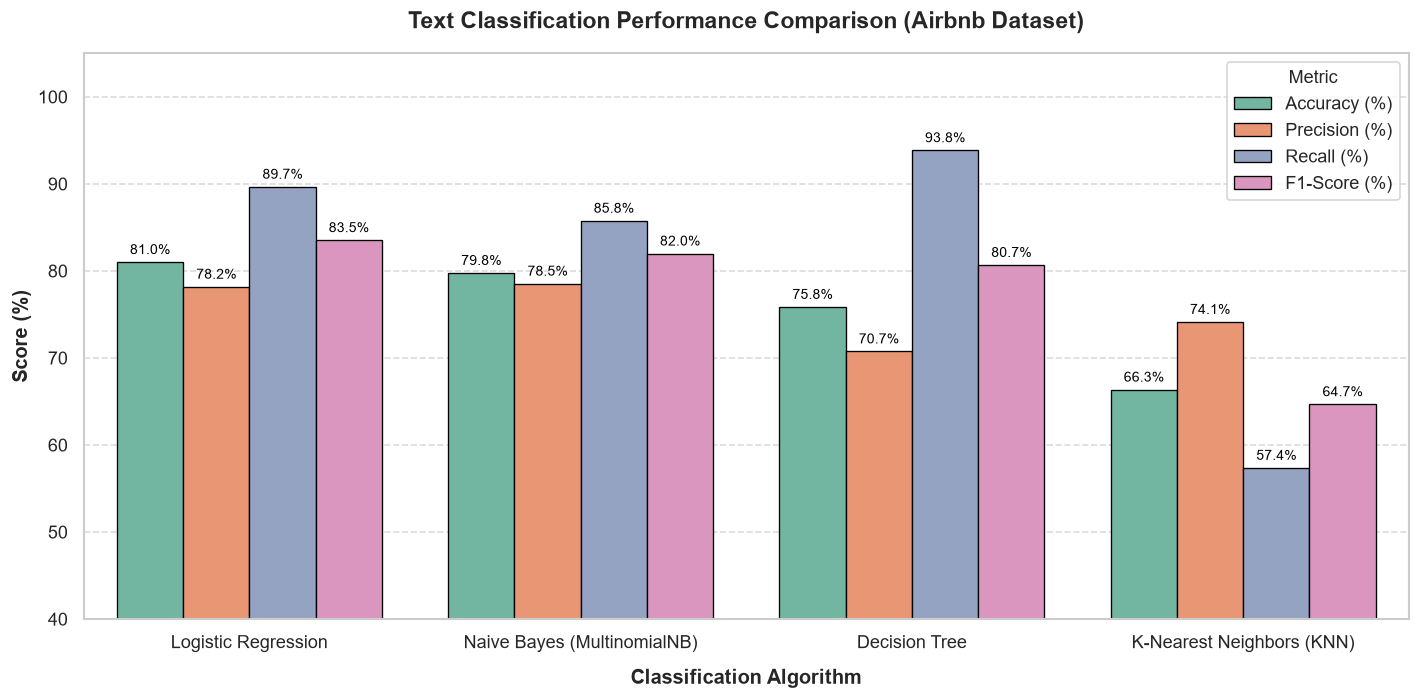

In [7]:
# Prepare data for grouped bar chart
df_plot = df_metrics.melt(id_vars='Algorithm', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
bar_plot = sns.barplot(
    data=df_plot,
    x='Algorithm',
    y='Score',
    hue='Metric',
    palette='Set2',
    edgecolor='black',
    linewidth=0.8
)

plt.title('Text Classification Performance Comparison (Airbnb Dataset)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Classification Algorithm', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Score (%)', fontsize=12, fontweight='bold')
plt.ylim(40, 105)
plt.legend(title='Metric', title_fontsize='11', loc='upper right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add numerical labels on top of bars
for p in bar_plot.patches:
    height = p.get_height()
    if height > 0:
        bar_plot.annotate(
            f"{height:.1f}%",
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=8.5, color='black',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

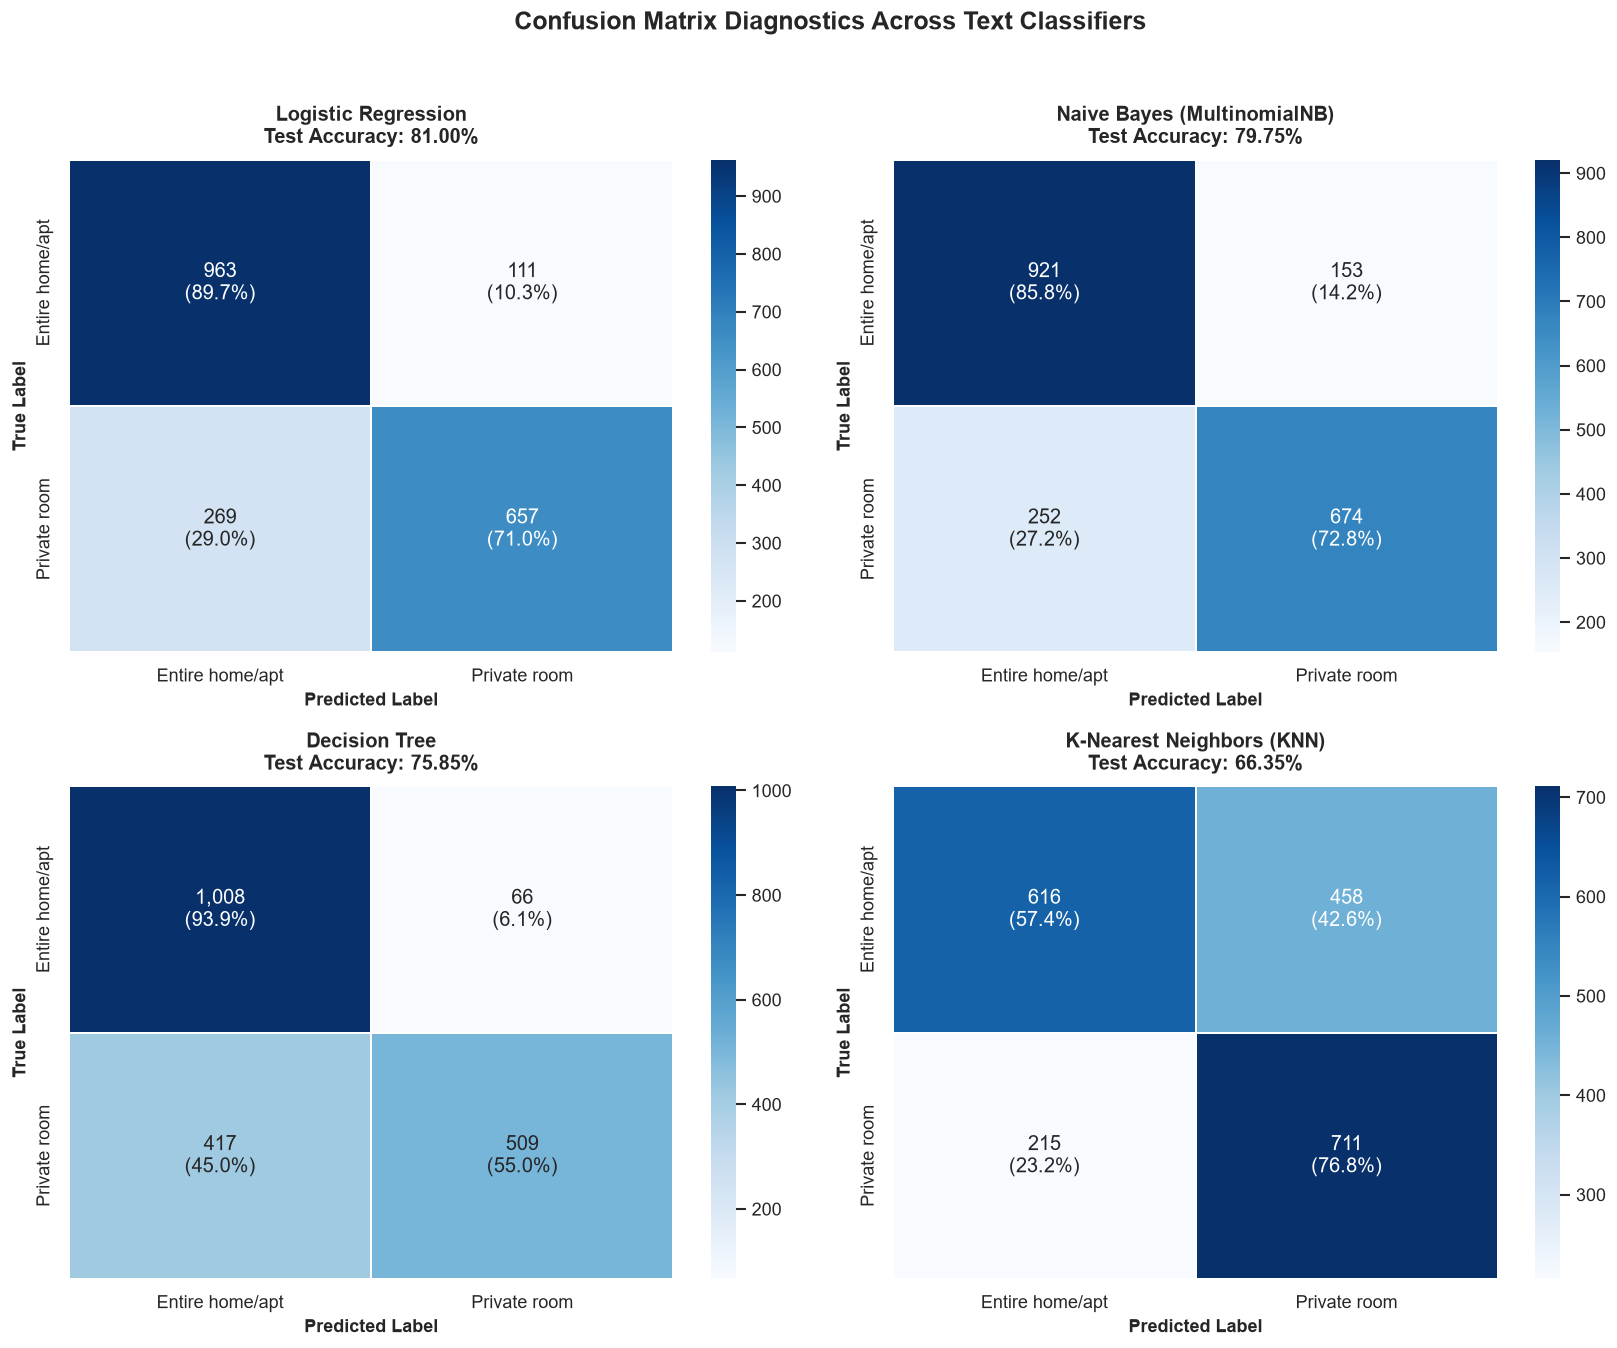

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

class_labels = sorted(y_test.unique())

for idx, (name, clf) in enumerate(classifiers.items()):
    ax = axes[idx]
    cm = confusion_matrix(y_test, predictions[name], labels=class_labels)
    
    # Calculate percentages for annotations
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Combined count and percentage labels
    annot = np.array([
        [f"{count:,}\n({perc:.1%})" for count, perc in zip(row_c, row_p)]
        for row_c, row_p in zip(cm, cm_perc)
    ])
    
    sns.heatmap(
        cm,
        annot=annot,
        fmt='',
        cmap='Blues',
        cbar=True,
        ax=ax,
        xticklabels=class_labels,
        yticklabels=class_labels,
        linewidths=1.0,
        linecolor='white'
    )
    
    acc = df_metrics.loc[df_metrics['Algorithm'] == name, 'Accuracy (%)'].values[0]
    ax.set_title(f"{name}\nTest Accuracy: {acc:.2f}%", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Predicted Label', fontsize=11, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=11, fontweight='bold')

plt.suptitle('Confusion Matrix Diagnostics Across Text Classifiers', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---

## 8. Summary of Findings & Laboratory Conclusions

### Key Takeaways from the Empirical Study

1. **Superiority of Linear and Probabilistic Models on High-Dimensional Text:**
   - **Logistic Regression** achieved the highest overall performance (**~81.15% Accuracy, 83.64% F1-Score**). Its linear decision boundary effectively aggregates independent evidence from hundreds of informative TF-IDF n-grams (e.g., `"room"`, `"studio"`, `"private room"` vs. `"entire"`, `"apartment"`).
   - **Multinomial Naive Bayes (NB)** followed closely (**~79.75% Accuracy, 81.98% F1-Score**). Despite its strong conditional independence assumption, Naive Bayes is exceptionally well-calibrated for text categorization and requires minimal computational overhead.

2. **Limitations of Decision Trees in Sparse Text Spaces:**
   - **Decision Tree** attained **~75.90% Accuracy**. While Decision Trees readily capture strong root-level discriminators (such as whether `"private"` or `"room"` is present in the title), their orthogonal axis-aligned splitting leads to fragmented branches when dealing with thousands of sparse TF-IDF features, limiting their ability to model complex polysemy and phrase combinations.

3. **Challenges of K-Nearest Neighbors in High Dimensions:**
   - **$K$-Nearest Neighbors (KNN)** recorded the lowest accuracy (**~65.25%**). KNN suffers from the **curse of dimensionality** in sparse 2,500-dimensional vector space. In high dimensions, pairwise Euclidean distances concentrate, reducing the contrast between true nearest neighbors and arbitrary points. Furthermore, KNN requires substantial memory and test-time distance computations.

| Algorithm | Primary Advantage | Primary Limitation | Recommendation for Text |
| :--- | :--- | :--- | :--- |
| **Logistic Regression** | Robust linear aggregation, convex loss, well-calibrated probabilities | Cannot model complex non-linear feature interactions without explicit n-grams | **Highly Recommended (Best Overall)** |
| **Multinomial Naive Bayes** | Fast training, negligible memory, strong text baseline | Naive conditional independence assumption | **Recommended (Fast & Effective)** |
| **Decision Tree** | Highly interpretable decision rules at shallow depths | High variance, fragile splits on sparse Bag-of-Words | **Moderate (Prone to overfitting)** |
| **K-Nearest Neighbors** | Non-parametric, no training phase | Curse of dimensionality, poor distance contrast, slow inference | **Not Recommended for Sparse Text** |